# PathSnap Phase 3: Candidate and Label Analysis

This notebook reads the processed CSV artifacts produced by `src.pipeline.run_phase3`. It does not read raw `.route` files or regenerate Phase 2 outputs. The training route is used upstream only for training labels and candidate-recall evaluation; student-test rows must remain unlabelled.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed = project_root / "data" / "processed"
train = pd.read_csv(processed / "train_candidate_features.csv")
student_test = pd.read_csv(processed / "student_test_candidate_features.csv")
train_observations = pd.read_csv(processed / "train_observations.csv")
student_observations = pd.read_csv(processed / "student_test_observations.csv")
candidate_recall = pd.read_csv(processed / "candidate_recall.csv")
route_summary = pd.read_csv(processed / "route_summary.csv")
processing_issues = pd.read_csv(processed / "processing_issues.csv")

print(f"Processed directory: {processed}")
print(f"Train candidate rows: {len(train):,}")
print(f"Student-test candidate rows: {len(student_test):,}")

Processed directory: C:\Users\Yashita Anand\OneDrive\Desktop\Pathsnap\data\processed
Train candidate rows: 1,084,832
Student-test candidate rows: 103,737


## Candidate and label coverage

Candidate rows represent GPS-observation/arc pairs. An observation can have no candidate rows; this is reported in the per-observation tables. Training labels are nullable: only confidently aligned route matches receive a binary `is_match` value.

In [2]:
train_label_counts = train_observations["label_status"].value_counts(dropna=False).rename_axis("label_status").to_frame("observation_count")
display(train_label_counts)
display(
    train_observations.groupby("trip_id", as_index=False).agg(
        gps_observation_count=("gps_observation_index", "size"),
        observations_with_candidates=("candidate_count", lambda values: int((values > 0).sum())),
        labelled_observations=("label_status", lambda values: int((values == "labelled").sum())),
    ).describe(include="all")
)

,observation_count
label_status,
labelled,126767
ambiguous,58494
no_candidate,22576
infeasible,427
component_conflict,153


,trip_id,gps_observation_count,observations_with_candidates,labelled_observations
count,80.000000,80.000000,80.000000,80.000000
mean,49.537500,2605.212500,2377.337500,1584.587500
std,28.948642,3312.345399,2667.477109,2141.383823
min,1.000000,361.000000,361.000000,0.000000
25%,25.750000,945.750000,945.750000,500.500000
50%,47.500000,1529.000000,1529.000000,948.500000
75%,74.250000,2792.750000,2784.250000,1791.250000
max,99.000000,19313.000000,15764.000000,14307.000000


## Candidate recall by search radius

Recall is measured against reference labels aligned from route arcs within the 50 m reference radius, without the top-8 cap. It is conditional on those confident reference labels and is not an independent ground-truth accuracy estimate.

,search_radius_m,reference_label_count,candidate_hits,candidate_recall,label_coverage,observations_with_candidates,observations_without_candidates
0,25.0,126767,123851,0.976997,0.608237,187028,21389
1,50.0,126767,125938,0.993460,0.608237,190187,18230
2,75.0,126767,125938,0.993460,0.608237,194809,13608
3,100.0,126767,125938,0.993460,0.608237,207000,1417


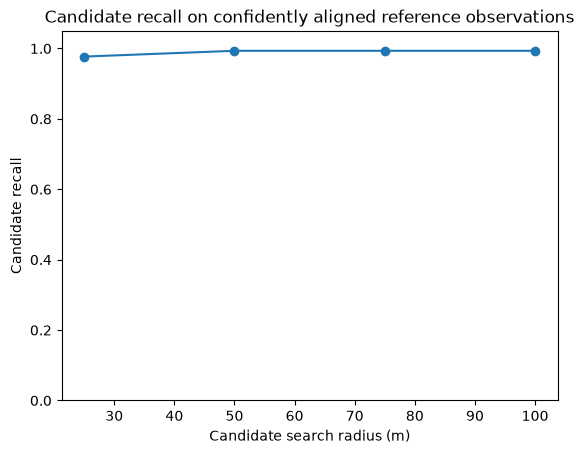

In [3]:
display(candidate_recall)
if not candidate_recall.empty:
    ax = candidate_recall.plot(
        x="search_radius_m", y="candidate_recall", marker="o", legend=False,
        title="Candidate recall on confidently aligned reference observations"
    )
    ax.set_xlabel("Candidate search radius (m)")
    ax.set_ylabel("Candidate recall")
    ax.set_ylim(0, 1.05)
    plt.show()

## Route components and processing issues

Disconnected directed route transitions are split into separate alignment components. The issue table retains processing limitations such as unavailable road arcs; it does not fabricate candidates or labels.

In [4]:
display(route_summary.describe(include="all"))
display(processing_issues.groupby(["dataset_split", "issue_type"], dropna=False).size().rename("trip_count").reset_index())
display(processing_issues.head(20))

,trip_id,route_position_count,route_component_count,disconnected_transition_count,repeated_route_position_count,labelled_observation_count,ambiguous_observation_count,unlabelled_observation_count
count,80.000000,80.000000,80.00000,80.00000,80.000000,80.000000,80.000000,80.000000
mean,49.537500,391.700000,1.16250,0.16250,0.837500,1584.587500,731.175000,1020.625000
std,28.948642,361.165497,0.48896,0.48896,3.773471,2141.383823,767.704861,2101.742685
min,1.000000,59.000000,1.00000,0.00000,0.000000,0.000000,65.000000,65.000000
25%,25.750000,168.250000,1.00000,0.00000,0.000000,500.500000,304.750000,310.500000
50%,47.500000,280.000000,1.00000,0.00000,0.000000,948.500000,478.000000,516.500000
75%,74.250000,480.500000,1.00000,0.00000,0.000000,1791.250000,821.250000,947.750000
max,99.000000,2266.000000,4.00000,3.00000,29.000000,14307.000000,3943.000000,17762.000000


,dataset_split,issue_type,trip_count
0,student_test,missing_arcs,1


,trip_id,dataset_split,issue_type,description
0,0,student_test,missing_arcs,Required arc file was not found: data\student_...


## Feature distributions and leakage guard

The plotted distances are in metres. Heading consistency is cosine of the smallest angular difference (range `[-1, 1]`) and is available only when both GPS heading and candidate bearing are defined. Candidate and route identifiers and label metadata are bookkeeping fields, not model inputs.

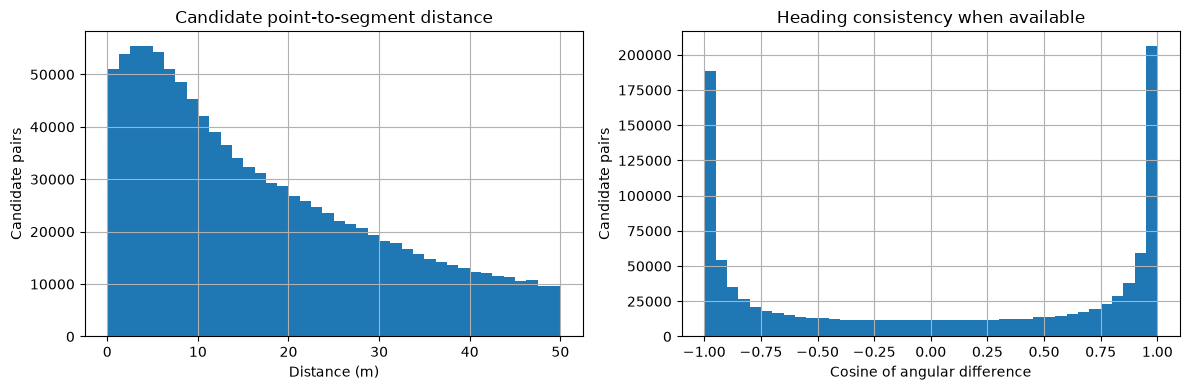

Leakage guard passed; 17 numeric features are available for model review.


In [5]:
if not train.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    train["point_to_segment_distance_m"].hist(bins=40, ax=axes[0])
    axes[0].set_title("Candidate point-to-segment distance")
    axes[0].set_xlabel("Distance (m)")
    axes[0].set_ylabel("Candidate pairs")
    available = train["gps_heading_available"].eq(1) & train["candidate_bearing_available"].eq(1)
    train.loc[available, "heading_consistency"].hist(bins=40, ax=axes[1])
    axes[1].set_title("Heading consistency when available")
    axes[1].set_xlabel("Cosine of angular difference")
    axes[1].set_ylabel("Candidate pairs")
    plt.tight_layout()
    plt.show()

forbidden_student_columns = {"is_match", "label_arc_id", "label_route_position", "label_status", "alignment_component", "route", "route_position"}
assert not forbidden_student_columns.intersection(student_test.columns)
model_feature_columns = [
    column for column in train.columns
    if column not in {
        "trip_id", "gps_observation_index", "candidate_arc_id", "dataset_split",
        "label_arc_id", "label_route_position", "label_status", "alignment_component", "is_match"
    }
]
assert not any("route" in column.lower() for column in model_feature_columns)
print(f"Leakage guard passed; {len(model_feature_columns)} numeric features are available for model review.")